# Is C_l^EB implemented in this CLASS build?

Runs the compiled `class` binary (no classy rebuild needed) and checks:
1. the output header lists an `EB` column,
2. EB, TB and BB are exactly 0 with `birefringence_A = 0`,
3. EB is non-zero for `A != 0`, and scales ~ linearly with A (BB ~ A^2).

In [1]:
import os, subprocess, tempfile
import numpy as np
import matplotlib.pyplot as plt

# repo root = parent of notebooks/ (adjust if you run from elsewhere)
CLASS_DIR = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
print('CLASS_DIR =', CLASS_DIR)

# rebuild so the binary matches the current sources (fast if nothing changed)
r = subprocess.run(['make', '-j4', 'class'], cwd=CLASS_DIR, capture_output=True, text=True)
print('make exit code:', r.returncode)
if r.returncode: print(r.stderr[-3000:])

CLASS_DIR = /home/robert/cosmology/class_v3.4.0
make exit code: 0


In [2]:
def run_class(A, L=1e-2, hierarchy='tam', lmax=800, tag=None):
    """Run CLASS and return (column_names, dict name->array)."""
    tag = tag or f'A{A:g}_{hierarchy}'
    tmp = tempfile.mkdtemp()
    ini = os.path.join(tmp, 'run.ini')
    root = os.path.join(tmp, tag + '_')
    with open(ini, 'w') as f:
        f.write(f"""output = tCl,pCl
lensing = no
l_max_scalars = {lmax}
hierarchy = {hierarchy}
birefringence_A = {A}
birefringence_L = {L}
root = {root}
write_parameters = no
overwrite_root = yes
""")
    r = subprocess.run([os.path.join(CLASS_DIR, 'class'), ini], cwd=CLASS_DIR, capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(r.stdout[-2000:] + r.stderr[-2000:])
    fn = [x for x in os.listdir(tmp) if x.endswith('cl.dat')][0]
    path = os.path.join(tmp, fn)
    header = [l for l in open(path) if l.startswith('# 1:l')][0]
    names = [h.split(':')[1] for h in header[1:].split() if ':' in h]
    data = np.loadtxt(path)
    return names, {n: data[:, i] for i, n in enumerate(names)}

In [3]:
# 1) is there an EB column at all?
names0, cl0 = run_class(0.0)
print('columns:', names0)
print('EB column present:', 'EB' in names0)

columns: ['l', 'TT', 'EE', 'XX', 'TE', 'BB', 'EB', 'TB']
EB column present: True


In [4]:
# 2) A=0 baseline and 3) A != 0
A_test = 1e-3
names1, cl1 = run_class(A_test)
l = cl1['l']

for spec in ['EB', 'TB', 'BB']:
    print(f"{spec}:  max|C_l(A=0)| = {np.abs(cl0[spec]).max():.3e}   max|C_l(A={A_test:g})| = {np.abs(cl1[spec]).max():.3e}")

print('\nEB implemented and sourced by birefringence:',
      'EB' in names1 and np.abs(cl0['EB']).max() == 0 and np.abs(cl1['EB']).max() > 0)

EB:  max|C_l(A=0)| = 0.000e+00   max|C_l(A=0.001)| = 8.919e-16
TB:  max|C_l(A=0)| = 0.000e+00   max|C_l(A=0.001)| = 4.021e-15
BB:  max|C_l(A=0)| = 0.000e+00   max|C_l(A=0.001)| = 1.666e-19

EB implemented and sourced by birefringence: True


In [5]:
# scaling check: EB ~ A, BB ~ A^2  (expect ratios ~ 10 and ~ 100 for A -> 10 A)
_, cl2 = run_class(10*A_test)
sel = (l >= 50)
print('EB(10A)/EB(A) median:', np.median(cl2['EB'][sel]/cl1['EB'][sel]))
print('BB(10A)/BB(A) median:', np.median(cl2['BB'][sel]/cl1['BB'][sel]))

EB(10A)/EB(A) median: 9.99996598152312
BB(10A)/BB(A) median: 99.99975075282049


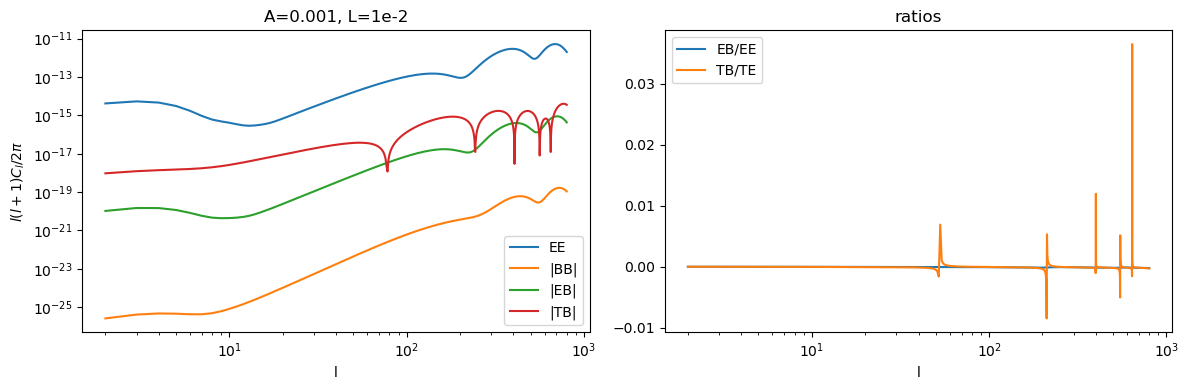

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(l, cl1['EE'], label='EE')
ax[0].loglog(l, np.abs(cl1['BB']), label='|BB|')
ax[0].loglog(l, np.abs(cl1['EB']), label='|EB|')
ax[0].loglog(l, np.abs(cl1['TB']), label='|TB|')
ax[0].set_xlabel('l'); ax[0].set_ylabel(r'$l(l+1)C_l/2\pi$'); ax[0].legend(); ax[0].set_title(f'A={A_test:g}, L=1e-2')
ax[1].semilogx(l, cl1['EB']/cl1['EE'], label='EB/EE')
ax[1].semilogx(l, cl1['TB']/cl1['TE'], label='TB/TE')
ax[1].set_xlabel('l'); ax[1].legend(); ax[1].set_title('ratios')
plt.tight_layout(); plt.show()